# Лабораторна робота №2: Зниження розмірності, кластеризація та класифікація текстових даних

**Виконала:** студентка групи ФБ-62мп Шукалович Марія

**Мета роботи:** ознайомитися з методами зниження розмірності (PCA, t-SNE), кластерного аналізу (K-Means), а також з обробкою та класифікацією текстових даних з використанням бібліотеки Scikit-learn.

**Дані:** для зниження розмірності та кластеризації використано датасет [Predict Students' Dropout and Academic Success](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) з лабораторної роботи №1 (4 424 студенти, 36 ознак, 3 класи: Dropout, Enrolled, Graduate). Для класифікації текстів використано датасет [Twenty Newsgroups](https://archive.ics.uci.edu/dataset/113/twenty+newsgroups) (UCI Machine Learning Repository, ліцензія CC BY 4.0).

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() - 1)
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from wordcloud import WordCloud

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42

## Зниження розмірності та візуалізація даних

Використовуємо датасет з лабораторної роботи №1 і таку саму попередню обробку: очищаємо назви колонок, рідкісні коди номінальних ознак (менше 1 % рядків) об'єднуємо в категорію «інше» і застосовуємо one-hot кодування. Цільову змінну кодуємо так: Dropout = 0, Enrolled = 1, Graduate = 2.

In [2]:
df = pd.read_csv("data.csv", sep=";")
df.columns = (df.columns.str.strip()
              .str.replace("Curricular units ", "", regex=False)
              .str.replace("Nacionality", "Nationality", regex=False))
target = "Target"
class_names = ["Dropout", "Enrolled", "Graduate"]
nominal_cols = ["Marital status", "Application mode", "Course", "Previous qualification", "Nationality",
                "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
binary_cols = [c for c in df.columns if c != target and df[c].nunique() == 2]
numeric_cols = [c for c in df.columns if c not in nominal_cols + binary_cols + [target]]

data = df.copy()
data[target] = data[target].map({name: i for i, name in enumerate(class_names)})
min_count = int(0.01 * len(data))
for col in nominal_cols:
    counts = data[col].value_counts()
    data[col] = data[col].where(~data[col].isin(counts[counts < min_count].index), -1)
data_encoded = pd.get_dummies(data, columns=nominal_cols, dtype=int)
X = data_encoded.drop(columns=target)
y = data_encoded[target]

print("Розмір датасета (рядки, колонки):", df.shape)
print("Ознак після one-hot кодування:", X.shape[1])
class_counts = df[target].value_counts().reindex(class_names)
display(pd.DataFrame({"Кількість": class_counts, "Частка": (class_counts / len(df)).round(3)}))

Розмір датасета (рядки, колонки): (4424, 37)
Ознак після one-hot кодування: 107


,Кількість,Частка
Target,,
Dropout,1421,0.321
Enrolled,794,0.179
Graduate,2209,0.499


Як і в лабораторній роботі №1, ділимо дані на навчальну та тестову вибірки у пропорції 80/20 зі стратифікацією і стандартизуємо лише 19 числових ознак. Бінарні та one-hot колонки залишаються зі значеннями 0 і 1. `StandardScaler` навчаємо тільки на навчальній вибірці.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
scaler = StandardScaler()
X_train_scaled, X_test_scaled = X_train.copy(), X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])
print("Train:", X_train_scaled.shape, "| Test:", X_test_scaled.shape)

Train: (3539, 107) | Test: (885, 107)


### Метод головних компонент (PCA)

PCA будує нові ознаки (головні компоненти), які є лінійними комбінаціями вихідних і зберігають якомога більше дисперсії даних. Кількість компонент обираємо так, щоб зберегти 95 % дисперсії. PCA навчаємо тільки на навчальній вибірці, а тестову лише перетворюємо.

Ознак до PCA: 107
Компонент після PCA: 50
Збережена частка дисперсії: 0.9506


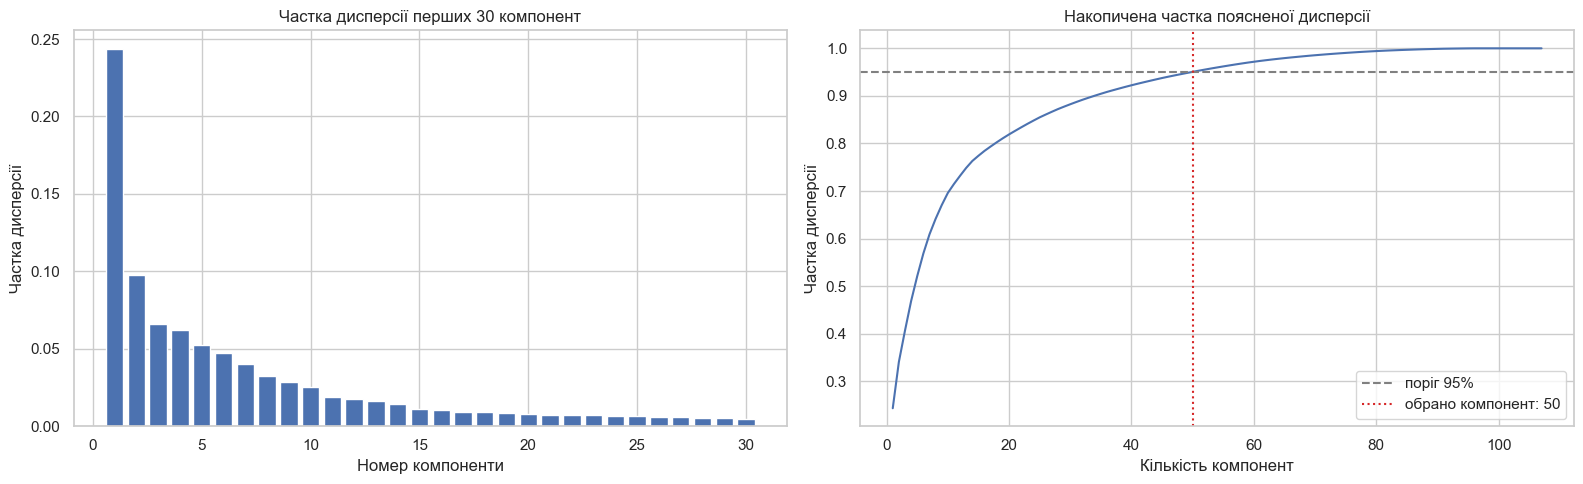

In [4]:
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("Ознак до PCA:", X_train_scaled.shape[1])
print("Компонент після PCA:", pca.n_components_)
print("Збережена частка дисперсії:", round(pca.explained_variance_ratio_.sum(), 4))

full_pca = PCA(random_state=RANDOM_STATE).fit(X_train_scaled)
cumulative = np.cumsum(full_pca.explained_variance_ratio_)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(range(1, 31), full_pca.explained_variance_ratio_[:30])
axes[0].set_title("Частка дисперсії перших 30 компонент")
axes[0].set_xlabel("Номер компоненти")
axes[0].set_ylabel("Частка дисперсії")
axes[1].plot(range(1, len(cumulative) + 1), cumulative)
axes[1].axhline(0.95, color="gray", linestyle="--", label="поріг 95%")
axes[1].axvline(pca.n_components_, color="tab:red", linestyle=":", label=f"обрано компонент: {pca.n_components_}")
axes[1].set_title("Накопичена частка поясненої дисперсії")
axes[1].set_xlabel("Кількість компонент")
axes[1].set_ylabel("Частка дисперсії")
axes[1].legend()
plt.tight_layout()
plt.show()

Щоб зберегти 95 % дисперсії, достатньо 50 компонент замість 107 ознак, тобто кількість ознак зменшилась на 53 %. Перша компонента пояснює 24.3 % дисперсії, перші 10 компонент разом майже 70 %, а 80 % дисперсії зберігають уже 18 компонент.

Стиснення можливе з двох причин. По-перше, багато числових ознак сильно корелюють між собою (наприклад, показники 1-го і 2-го семестрів, див. heatmap у лабораторній роботі №1), тому їх можна описати меншою кількістю компонент. По-друге, one-hot колонки мають малу дисперсію (не більше 0.25 кожна), тож разом дають лише 22 % загальної дисперсії, і PCA майже не витрачає на них компонент.

Ознаки з найбільшим внеском у перші три компоненти (у дужках навантаження):

In [5]:
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])
display(pd.DataFrame({pc: [f"{name} ({loadings.loc[name, pc]:+.2f})" for name in loadings[pc].abs().nlargest(6).index]
                      for pc in loadings.columns}))

,PC1,PC2,PC3
0,1st sem (enrolled) (+0.36),Age at enrollment (+0.42),Admission grade (+0.63)
1,1st sem (approved) (+0.36),2nd sem (grade) (-0.37),Previous qualification (grade) (+0.63)
2,2nd sem (enrolled) (+0.35),1st sem (grade) (-0.36),GDP (-0.23)
3,2nd sem (approved) (+0.34),1st sem (credited) (+0.28),Unemployment rate (+0.21)
4,1st sem (evaluations) (+0.30),2nd sem (credited) (+0.27),Application order (-0.20)
5,2nd sem (credited) (+0.30),Application order (-0.25),1st sem (without evaluations) (+0.16)


Перша компонента описує академічне навантаження та успішність: кількість записаних, складених, оцінених і перезарахованих дисциплін в обох семестрах. Друга пов'язана з віком і кількістю перезарахованих дисциплін, а оцінки за семестри входять у неї з протилежним знаком, тобто вона виділяє старших студентів з перезарахуванням і нижчими оцінками. Третя описує попередню успішність: вступну оцінку та оцінку попередньої освіти.

### Класифікація до та після PCA

Порівнюємо алгоритми з лабораторної роботи №1 з тими самими гіперпараметрами: SVM (C = 100, gamma = 0.001, найкраща модель лабораторної роботи №1), kNN (k = 11) і Random Forest. Кожну модель навчаємо на вихідних 107 ознаках і на 50 головних компонентах. Час навчання і прогнозу вимірюємо тричі й беремо медіану, щоб зменшити вплив випадкових коливань.

Ознак  Accuracy  F1 (macro)  F1 Dropout  \
Модель                   Дані                                                 
SVM (C=100, gamma=0.001) до PCA       107    0.7627      0.6890      0.7628   
                         після PCA     50    0.7751      0.7069      0.7831   
kNN (k=11)               до PCA       107    0.7062      0.6055      0.6940   
                         після PCA     50    0.7017      0.6005      0.7002   
Random Forest            до PCA       107    0.7774      0.6858      0.7849   
                         після PCA     50    0.7537      0.6372      0.7865   

                                    F1 Enrolled  F1 Graduate  Час навчання, с  \
Модель                   Дані                                                   
SVM (C=100, gamma=0.001) до PCA          0.4468       0.8574           0.8389   
                         після PCA       0.4835       0.8541           0.6471   
kNN (k=11)               до PCA          0.3207       0.8020           0.0095   
                         після PCA       0.3008       0.8004           0.0019   
Random Forest            до PCA          0.4083       0.8642           0.3752   
                         після PCA       0.2911       0.8342           0.6748   

                                    Час прогнозу, с  
Модель                   Дані                        
SVM (C=100, gamma=0.001) до PCA              0.2893  
                         після PCA           0.2152  
kNN (k=11)               до PCA              0.1105  
                         після PCA           0.0204  
Random Forest            до PCA              0.0644  
                         після PCA           0.0634

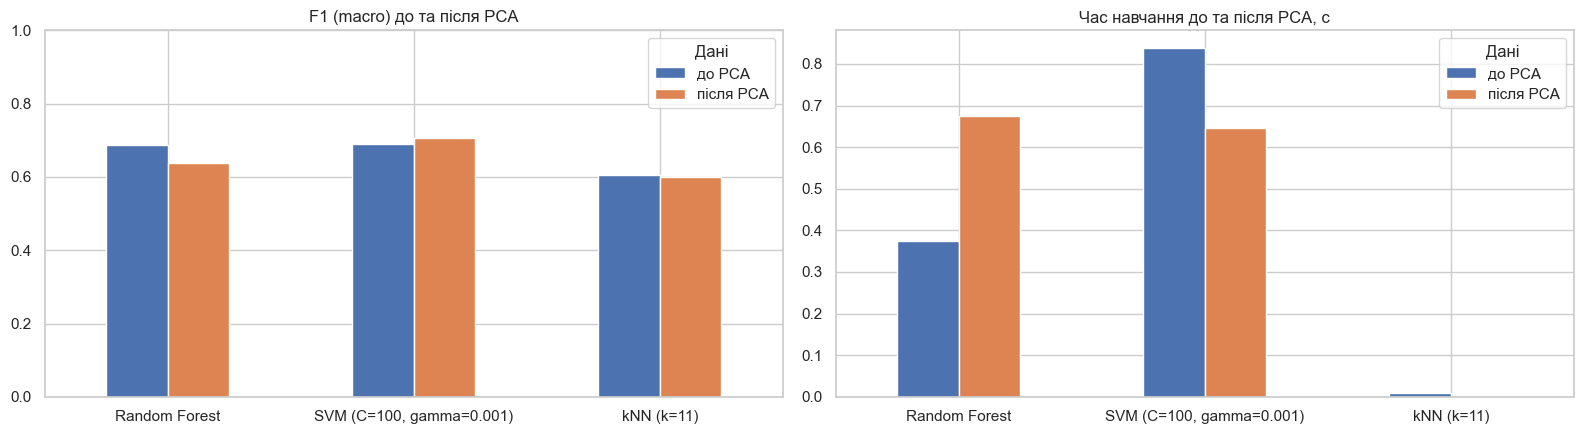

In [6]:
models = {
    "SVM (C=100, gamma=0.001)": SVC(kernel="rbf", C=100, gamma=0.001),
    "kNN (k=11)": KNeighborsClassifier(n_neighbors=11),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}


def evaluate(model, X_tr, X_te, repeats=3):
    fit_times, predict_times = [], []
    for _ in range(repeats):
        start = time.perf_counter()
        model.fit(X_tr, y_train)
        fit_times.append(time.perf_counter() - start)
        start = time.perf_counter()
        y_pred = model.predict(X_te)
        predict_times.append(time.perf_counter() - start)
    f1_per_class = f1_score(y_test, y_pred, average=None)
    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
        **{f"F1 {name}": value for name, value in zip(class_names, f1_per_class)},
        "Час навчання, с": np.median(fit_times),
        "Час прогнозу, с": np.median(predict_times),
    }


rows = []
for name, model in models.items():
    for stage, X_tr, X_te in [("до PCA", X_train_scaled, X_test_scaled), ("після PCA", X_train_pca, X_test_pca)]:
        rows.append({"Модель": name, "Дані": stage, "Ознак": X_tr.shape[1], **evaluate(model, X_tr, X_te)})
pca_results = pd.DataFrame(rows).set_index(["Модель", "Дані"])
display(pca_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
pca_results["F1 (macro)"].unstack().plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("F1 (macro) до та після PCA")
axes[0].set_ylim(0, 1)
pca_results["Час навчання, с"].unstack().plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Час навчання до та після PCA, с")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### Висновки щодо PCA

- Кількість ознак: PCA зменшив кількість ознак зі 107 до 50 (на 53 %) і зберіг 95 % дисперсії.
- Якість для SVM навіть трохи зросла: accuracy з 0.763 до 0.775, macro F1 з 0.689 до 0.707, переважно завдяки класу Enrolled (F1 з 0.447 до 0.484). Відкинуті 5 % дисперсії містили переважно шум і рідкісні категорії, які лише заважали моделі.
- Для kNN якість майже не змінилась (accuracy 0.706 і 0.702, macro F1 0.606 і 0.600). PCA без масштабування компонент є проєкцією, яка майже зберігає відстані між об'єктами, а саме на відстанях ґрунтуються kNN і SVM з RBF ядром.
- Для Random Forest якість знизилась: accuracy з 0.777 до 0.754, macro F1 з 0.686 до 0.637, найбільше для класу Enrolled (F1 з 0.408 до 0.291). Дерева розбивають дані за окремими ознаками, а після PCA кожна компонента змішує багато ознак, тому найважливіші сигнали (наприклад, кількість складених дисциплін) розмиваються.
- Час: SVM після PCA навчається і прогнозує швидше, бо ядрові обчислення виконуються в 50 вимірах замість 107. kNN фактично не навчається (лише запам'ятовує дані), а його прогноз після PCA також швидший. Random Forest, навпаки, навчається в кілька разів довше: до PCA більшість ознак бінарні (для кожної є лише один можливий поріг розбиття), а всі 50 компонент неперервні, тож дерева перебирають набагато більше порогів. Отже, зменшення кількості ознак не завжди пришвидшує навчання, ефект залежить від алгоритму. Точні значення часу залежать від комп'ютера й трохи змінюються між запусками.

### Візуалізація за допомогою t-SNE

t-SNE розміщує об'єкти на площині так, щоб близькі в просторі 107 ознак студенти залишалися поруч. Будуємо t-SNE для всіх 4 424 студентів (числові ознаки стандартизуємо на всіх даних, бо тут модель не навчається). На першому графіку колір позначає справжній клас, на двох інших кількість складених дисциплін у 2-му семестрі та кількість перезарахованих дисциплін у 1-му семестрі: вони допомагають пояснити структуру карти.

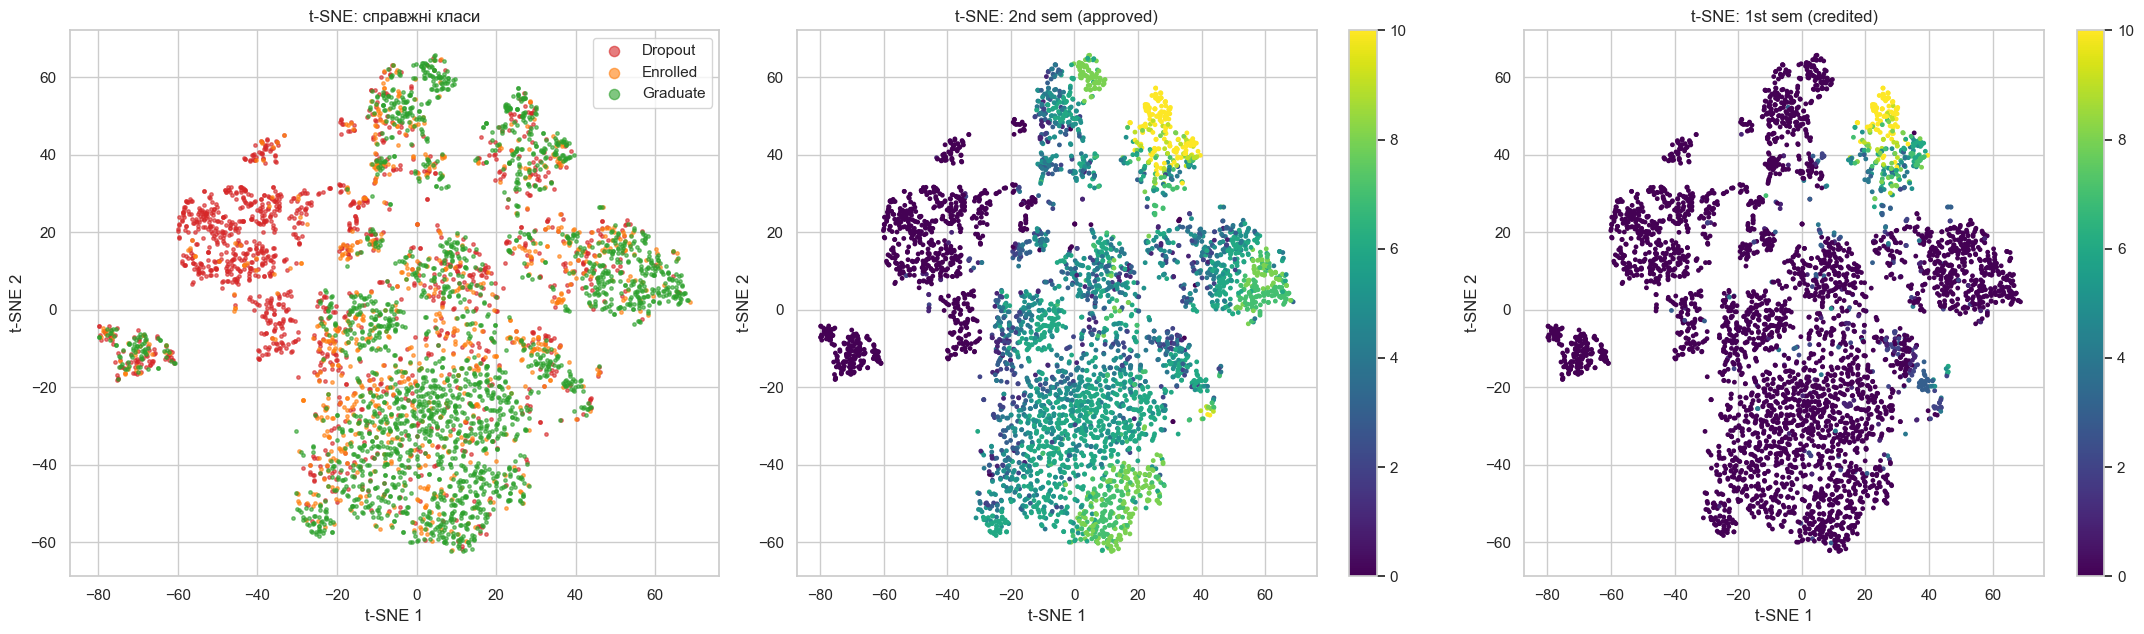

In [7]:
X_all = X.copy()
X_all[numeric_cols] = StandardScaler().fit_transform(X[numeric_cols])
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_all)

class_colors = {"Dropout": "tab:red", "Enrolled": "tab:orange", "Graduate": "tab:green"}
fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
for i, name in enumerate(class_names):
    mask = (y == i).to_numpy()
    axes[0].scatter(X_tsne[mask, 0], X_tsne[mask, 1], s=6, alpha=0.6, color=class_colors[name], label=name)
axes[0].legend(markerscale=3)
axes[0].set_title("t-SNE: справжні класи")
for ax, col in zip(axes[1:], ["2nd sem (approved)", "1st sem (credited)"]):
    points = ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=df[col], cmap="viridis", vmax=10, s=6)
    fig.colorbar(points, ax=ax)
    ax.set_title(f"t-SNE: {col}")
for ax in axes:
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

На карті є окремий щільний острів. Перевіримо студентів, у яких немає жодної дисципліни в обох семестрах:

In [8]:
zero_units = (df["1st sem (enrolled)"] == 0) & (df["2nd sem (enrolled)"] == 0)
print("Студентів без жодної дисципліни в обох семестрах:", zero_units.sum())
print("Їхні курси:", df.loc[zero_units, "Course"].value_counts().to_dict())
print("Їхні класи:", df.loc[zero_units, target].value_counts().to_dict())

Студентів без жодної дисципліни в обох семестрах: 180
Їхні курси: {171: 180}
Їхні класи: {'Dropout': 77, 'Graduate': 75, 'Enrolled': 28}


Класи на карті розділяються лише частково. Відраховані студенти (Dropout) зосереджені в області, де кількість складених дисциплін близька до нуля (темні точки на середньому графіку). Випускники (Graduate) переважають там, де студенти складають більшість дисциплін. Клас Enrolled не має власної області: ці студенти розкидані по центральній частині карти й перемішані з випускниками та частиною відрахованих, бо за показниками першого року вони схожі на обидві групи. Саме тому Enrolled найгірше розпізнають класифікатори.

Окремі групи на карті утворюють студенти з великою кількістю перезарахованих дисциплін (світлі точки на третьому графіку) і студенти окремих курсів. Окремий острів складається зі 180 студентів курсу з кодом 171, у яких немає жодної дисципліни в обох семестрах: усі їхні семестрові показники нульові, тому t-SNE збирає їх разом, хоча серед них є і відраховані (77), і випускники (75). Отже, головна структура даних визначається академічною успішністю, і вона добре узгоджується з класами Dropout і Graduate, але не з Enrolled.

## Кластерний аналіз

Кластеризуємо тих самих 4 424 студентів за тими самими 107 ознаками (числові ознаки стандартизовано). Мітки класів (`Target`) під час кластеризації не використовуються, вони потрібні лише для порівняння після неї. Класів лише 3, тому залишаємо всі.

### Вибір кількості кластерів

Для k від 2 до 10 обчислюємо inertia (сума квадратів відстаней об'єктів до центрів їхніх кластерів, для Elbow Method) і Silhouette Score (наскільки об'єкти ближчі до свого кластера, ніж до сусіднього; значення від -1 до 1, чим більше, тим краще). Лікоть шукаємо як точку, де нахил кривої inertia змінюється найсильніше.

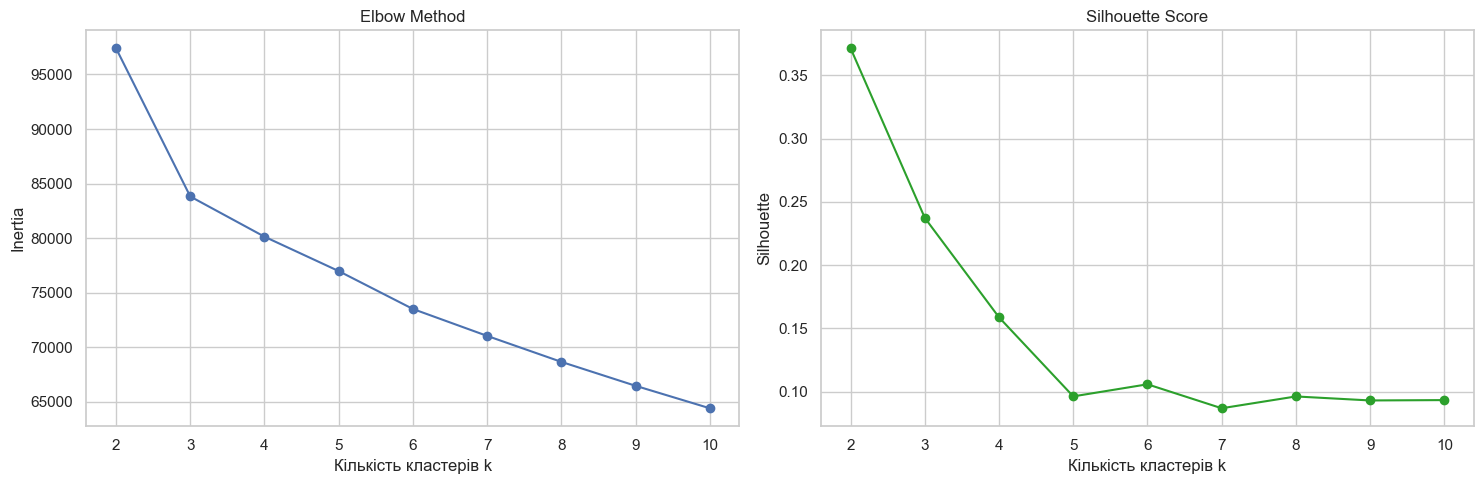

Лікоть кривої inertia: k = 3
Максимум Silhouette Score: k = 2


,Inertia,Silhouette
k,,
2,97396.5262,0.3714
3,83815.7193,0.2373
4,80129.5156,0.1588
5,76977.3292,0.0963
6,73503.2632,0.1059
7,71036.4330,0.0869
8,68654.2177,0.0963
9,66461.3929,0.0931
10,64402.9794,0.0934


In [9]:
k_values = list(range(2, 11))
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_all)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_all, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Кількість кластерів k")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_values, silhouettes, marker="o", color="tab:green")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Кількість кластерів k")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

elbow_k = k_values[int(np.argmax(np.diff(inertias, 2))) + 1]
silhouette_k = k_values[int(np.argmax(silhouettes))]
print("Лікоть кривої inertia: k =", elbow_k)
print("Максимум Silhouette Score: k =", silhouette_k)
display(pd.DataFrame({"k": k_values, "Inertia": inertias, "Silhouette": silhouettes}).set_index("k").round(4))

На кривій Elbow чіткий злам при k = 3: перехід від 2 до 3 кластерів зменшує inertia на 13.6 тис., а кожен наступний крок лише на 2.1 до 3.7 тис. Silhouette Score найбільший при k = 2 (0.371), другий за величиною при k = 3 (0.237), а для k від 4 і більше значно менший (0.16 і нижче). Перевіримо, що саме відокремлює розбиття на 2 кластери:

In [10]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_all)
display(df.groupby(km2.labels_)[["Age at enrollment", "1st sem (credited)", "1st sem (enrolled)", "2nd sem (approved)"]]
        .mean().round(2).assign(Студентів=np.bincount(km2.labels_)))
display(pd.crosstab(km2.labels_, df[target], rownames=["Кластер"]))
print("Adjusted Rand Index для k = 2:", round(adjusted_rand_score(y, km2.labels_), 4))

,Age at enrollment,1st sem (credited),1st sem (enrolled),2nd sem (approved),Студентів
0,28.73,8.58,13.14,9.89,285
1,22.89,0.17,5.80,4.06,4139


Target,Dropout,Enrolled,Graduate
Кластер,,,
0,68,37,180
1,1353,757,2029


Adjusted Rand Index для k = 2: -0.011


При k = 2 K-Means лише відокремлює невелику групу з 285 старших студентів (середній вік 28.7 року) з великою кількістю перезарахованих дисциплін (у середньому 8.6 у 1-му семестрі) від усіх інших. Ця група не пов'язана з результатом навчання: Adjusted Rand Index з класами близький до нуля (-0.011).

Тому обираємо k = 3. Це злам на кривій Elbow і другий найвищий Silhouette Score, а розбиття на 3 кластери дає більше інформації про студентів. До того ж кількість кластерів збігається з кількістю класів, що зручно для порівняння.

### Кластеризація та візуалізація у 2D

Виконуємо K-Means з k = 3. Щоб нумерація кластерів не залежала від випадкової ініціалізації, перенумеровуємо їх за зростанням середньої кількості складених дисциплін у 2-му семестрі. Нижче наведено профіль кожного кластера: середні значення ключових ознак (для бінарних ознак це частка студентів зі значенням 1).

In [11]:
kmeans = KMeans(n_clusters=elbow_k, n_init=10, random_state=RANDOM_STATE).fit(X_all)
order = df.groupby(kmeans.labels_)["2nd sem (approved)"].mean().sort_values().index
clusters = pd.Series(kmeans.labels_).map({old: new for new, old in enumerate(order, start=1)}).to_numpy()

key_cols = ["Age at enrollment", "Admission grade", "Scholarship holder", "Debtor", "Tuition fees up to date",
            "1st sem (credited)", "1st sem (enrolled)", "1st sem (approved)", "1st sem (grade)",
            "2nd sem (approved)", "2nd sem (grade)"]
print("Студентів у кластерах:", pd.Series(clusters).value_counts().sort_index().to_dict())
profile = df.groupby(clusters)[key_cols].mean().round(2)
profile.index = [f"Кластер {c}" for c in profile.index]
display(profile.T)

Студентів у кластерах: {1: 844, 2: 3307, 3: 273}


,Кластер 1,Кластер 2,Кластер 3
Age at enrollment,26.02,22.12,28.67
Admission grade,126.86,126.79,129.61
Scholarship holder,0.10,0.30,0.12
Debtor,0.18,0.09,0.14
Tuition fees up to date,0.70,0.92,0.91
1st sem (credited),0.04,0.22,8.78
1st sem (enrolled),4.36,6.18,13.30
1st sem (approved),0.34,5.24,11.70
1st sem (grade),1.83,12.72,12.66
2nd sem (approved),0.08,5.09,10.00


За профілем кластери легко інтерпретувати:

- Кластер 1 (844 студенти): невстигаючі. Вони майже не складають дисциплін (у середньому 0.34 у 1-му семестрі й 0.08 у 2-му), мають майже нульові оцінки, частіше мають борги (18 %), а вчасно оплачують навчання лише 70 %.
- Кластер 2 (3 307 студентів): основна група. Наймолодші (у середньому 22 роки), складають близько 5 дисциплін за семестр із середньою оцінкою 12.7 і 12.5 і найчастіше отримують стипендію (30 %).
- Кластер 3 (273 студенти): студенти з перезарахуванням. Старші (у середньому 28.7 року), мають у середньому 8.8 перезарахованих дисциплін у 1-му семестрі й тому значно більше записаних і складених дисциплін. Імовірно, це переведення з інших програм або друга вища освіта.

Візуалізуємо кластери у 2D за допомогою PCA (2 компоненти) і t-SNE з попереднього розділу. Поруч для порівняння показано справжні класи (кольори кластерів і класів навмисно різні).

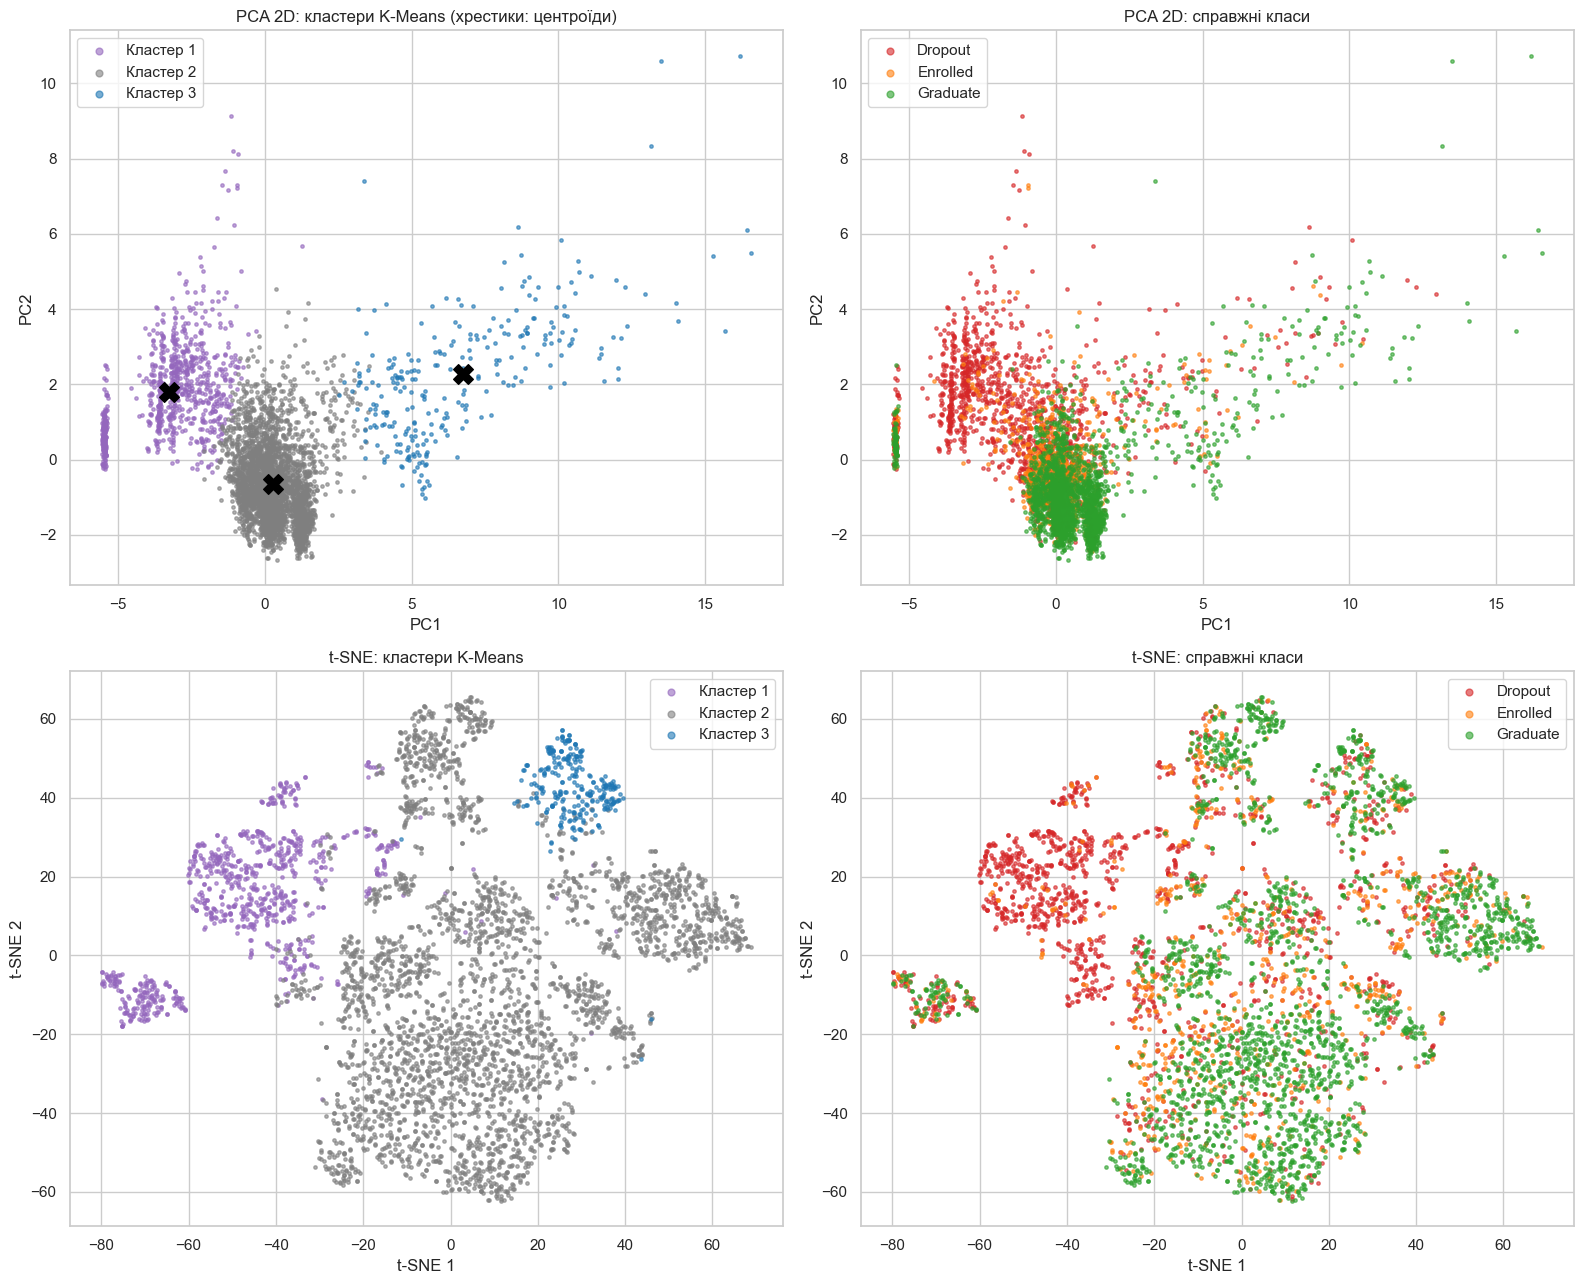

In [12]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_all_2d = pca_2d.fit_transform(X_all)
centers_2d = pca_2d.transform(pd.DataFrame(kmeans.cluster_centers_, columns=X_all.columns))
cluster_colors = {1: "tab:purple", 2: "tab:gray", 3: "tab:blue"}

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for row, points in enumerate([X_all_2d, X_tsne]):
    for c, color in cluster_colors.items():
        mask = clusters == c
        axes[row, 0].scatter(points[mask, 0], points[mask, 1], s=6, alpha=0.6, color=color, label=f"Кластер {c}")
    for i, name in enumerate(class_names):
        mask = (y == i).to_numpy()
        axes[row, 1].scatter(points[mask, 0], points[mask, 1], s=6, alpha=0.6, color=class_colors[name], label=name)
axes[0, 0].scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="X", s=200)
titles = [["PCA 2D: кластери K-Means (хрестики: центроїди)", "PCA 2D: справжні класи"],
          ["t-SNE: кластери K-Means", "t-SNE: справжні класи"]]
for row in range(2):
    for col in range(2):
        axes[row, col].set_title(titles[row][col])
        axes[row, col].set_xlabel("PC1" if row == 0 else "t-SNE 1")
        axes[row, col].set_ylabel("PC2" if row == 0 else "t-SNE 2")
        axes[row, col].legend(markerscale=2)
plt.tight_layout()
plt.show()

На проєкції PCA кластери розташовані вздовж першої компоненти (академічне навантаження та успішність): невстигаючі з одного боку, основна група в центрі, студенти з перезарахуванням з протилежного боку. На карті t-SNE кластери 1 і 3 також займають окремі області. Кластер 1 збігається з областю, де переважають відраховані студенти, і включає острів студентів курсу 171. Натомість усередині кластера 2 класи Enrolled і Graduate перемішані, і межі між ними не видно.

### Порівняння кластерів зі справжніми класами

Adjusted Rand Index (ARI) і Normalized Mutual Information (NMI) дорівнюють 1, якщо кластери повністю збігаються з класами, і близькі до 0, якщо зв'язку між ними немає.

In [13]:
print("Adjusted Rand Index:", round(adjusted_rand_score(y, clusters), 4))
print("Normalized Mutual Information:", round(normalized_mutual_info_score(y, clusters), 4))
cluster_labels = pd.Series([f"Кластер {c}" for c in clusters], name="Кластер")
counts = pd.crosstab(cluster_labels, df[target].rename("Клас"))[class_names]
print("Кількість студентів:")
display(counts.assign(Усього=counts.sum(axis=1)))
print("Склад кожного кластера (частки класів у рядку):")
display(counts.div(counts.sum(axis=1), axis=0).round(3))
print("Розподіл кожного класу між кластерами (частки в стовпці):")
display(counts.div(counts.sum(axis=0), axis=1).round(3))
print("Студенти без жодної дисципліни за кластерами:", cluster_labels[zero_units.to_numpy()].value_counts().to_dict())

Adjusted Rand Index: 0.1498
Normalized Mutual Information: 0.1571
Кількість студентів:


Клас,Dropout,Enrolled,Graduate,Усього
Кластер,,,,
Кластер 1,694,74,76,844
Кластер 2,663,684,1960,3307
Кластер 3,64,36,173,273


Склад кожного кластера (частки класів у рядку):


Клас,Dropout,Enrolled,Graduate
Кластер,,,
Кластер 1,0.822,0.088,0.090
Кластер 2,0.200,0.207,0.593
Кластер 3,0.234,0.132,0.634


Розподіл кожного класу між кластерами (частки в стовпці):


Клас,Dropout,Enrolled,Graduate
Кластер,,,
Кластер 1,0.488,0.093,0.034
Кластер 2,0.467,0.861,0.887
Кластер 3,0.045,0.045,0.078


Студенти без жодної дисципліни за кластерами: {'Кластер 1': 180}


### Висновки щодо кластеризації

- Доцільна кількість кластерів k = 3: це злам на кривій Elbow і другий найвищий Silhouette Score, тоді як k = 2 лише відокремлює студентів з перезарахуванням. Silhouette Score при k = 3 невисокий (0.237): кластери існують, але межі між ними розмиті.
- Кластерна структура відповідає класам лише частково. Кластер 1 (невстигаючі) на 82 % складається з відрахованих студентів, тобто K-Means фактично знайшов приблизно половину класу Dropout (49 % усіх відрахованих).
- Інші класи кластерами не відтворюються. Майже всі випускники (89 %) і студенти Enrolled (86 %) потрапили в кластер 2, а він складається з випускників лише на 59 % і приблизно порівну з Enrolled (21 %) і Dropout (20 %). Ще 47 % відрахованих теж опинилися в цьому кластері: за показниками першого року вони не відрізняються від тих, хто продовжує навчання, і відраховуються пізніше або з причин, яких немає в ознаках.
- Кластер 3 виділяється не результатом навчання, а траєкторією вступу (перезараховані дисципліни), і в ньому є всі три класи.
- Майже всі випускники в кластері 1 (75 із 76) є студентами курсу 171 без жодної дисципліни в даних: нульові показники роблять їх схожими на невстигаючих. Це особливість даних, а не помилка алгоритму.
- Загальна відповідність слабка: ARI 0.150, NMI 0.157. Отже, K-Means групує студентів за академічною поведінкою та траєкторією навчання, а не за підсумковим статусом. Кластер і клас збігаються лише там, де клас прямо відображається в ознаках (невстигаючі та Dropout), а статус Enrolled і частина відрахувань від наявних ознак залежать слабко.

## Обробка та класифікація текстових даних

Датасет Twenty Newsgroups містить повідомлення з 20 тематичних груп новин. Він доступний у scikit-learn через функцію `fetch_20newsgroups` (під час першого запуску дані завантажуються з інтернету). Класів багато, тому залишаємо 3 тематично різні: `comp.graphics` (комп'ютерна графіка), `rec.sport.hockey` (хокей) і `sci.space` (космос). Заголовки, підписи та цитати листів видаляємо (параметр `remove`), щоб модель навчалася на змісті повідомлень, а не на службових полях на кшталт адрес і назв організацій.

In [14]:
categories = ["comp.graphics", "rec.sport.hockey", "sci.space"]
newsgroups = fetch_20newsgroups(subset="all", categories=categories, remove=("headers", "footers", "quotes"),
                                shuffle=True, random_state=RANDOM_STATE)
texts = pd.DataFrame({"text": newsgroups.data, "label": np.array(newsgroups.target_names)[newsgroups.target]})
print("Кількість текстів:", len(texts))
display(texts["label"].value_counts().rename("Кількість").to_frame())

Кількість текстів: 2959


,Кількість
label,
rec.sport.hockey,999
sci.space,987
comp.graphics,973


### Передобробка текстів

Переводимо текст у нижній регістр, видаляємо адреси електронної пошти, посилання й доменні імена, цифри та пунктуацію, а також стоп-слова: стандартний англійський список scikit-learn, доповнений загальновживаними словами на кшталт like, know, think, які трапляються в усіх темах. Також видаляємо слова з однієї або двох літер. Тексти, у яких після очищення залишилося менше 3 слів, відкидаємо, бо за ними неможливо визначити тему.

In [15]:
stop_words = set(ENGLISH_STOP_WORDS) | {
    "like", "know", "think", "just", "don", "does", "doesn", "didn", "did", "isn", "use", "used", "using",
    "good", "people", "time", "way", "really", "want", "need", "make", "say", "said", "going", "thing",
    "things", "lot", "sure", "thanks", "right", "got", "let", "edu", "com",
}


def clean_text(text):
    text = text.lower()
    text = re.sub(r"\S+@\S+|http\S+|www\.\S+|\S+\.(?:com|edu|net|org|gov)\b\S*", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(word for word in text.split() if word not in stop_words and len(word) > 2)


texts["clean_text"] = texts["text"].apply(clean_text)
texts = texts[texts["clean_text"].str.split().str.len() >= 3].reset_index(drop=True)
print("Текстів після очищення:", len(texts))
display(texts["label"].value_counts().rename("Кількість").to_frame())
display(texts[["text", "clean_text", "label"]].head())

Текстів після очищення: 2841


,Кількість
label,
rec.sport.hockey,958
sci.space,947
comp.graphics,936


,text,clean_text,label
0,"\n Yes. There are many methods of rendering, raytracing is one of them.\nYou didn't say what you mean by renderi...",yes methods rendering raytracing mean rendering won guess methods rendering include pencil graph paper doing math ha...,comp.graphics
1,I've borrowed the 1992-93 version of this book from a friend...holy\nmoley! What a wealth of contacts. Five-hundre...,borrowed version book friend holy moley wealth contacts pages information electronic artists organizations globe ema...,comp.graphics
2,I have posted disp135.zip to alt.binaries.pictures.utilities\n\n\n****** You may distribute this program freely fo...,posted disp zip alt binaries pictures utilities distribute program freely non commercial fee gained warranty author ...,comp.graphics
3,A good reason (which is why many companies use it) for 48 bits / pixel\nis so you can use double buffering (for anim...,reason companies bits pixel double buffering animating scenes bit planes write background flip entire screen updates...,comp.graphics
4,"I'm working on a system which uses a given set of 3D key frame\npositions (x,y,z) to control an imaginary camera mov...",working uses given set key frame positions control imaginary camera movement kochanek bartels splines described sigg...,comp.graphics


### WordCloud для кожного класу

Розмір слова пропорційний його частоті в класі, а параметр `collocations=True` додає до хмари стійкі словосполучення з двох слів. Під хмарами наведено 10 найчастіших слів кожного класу.

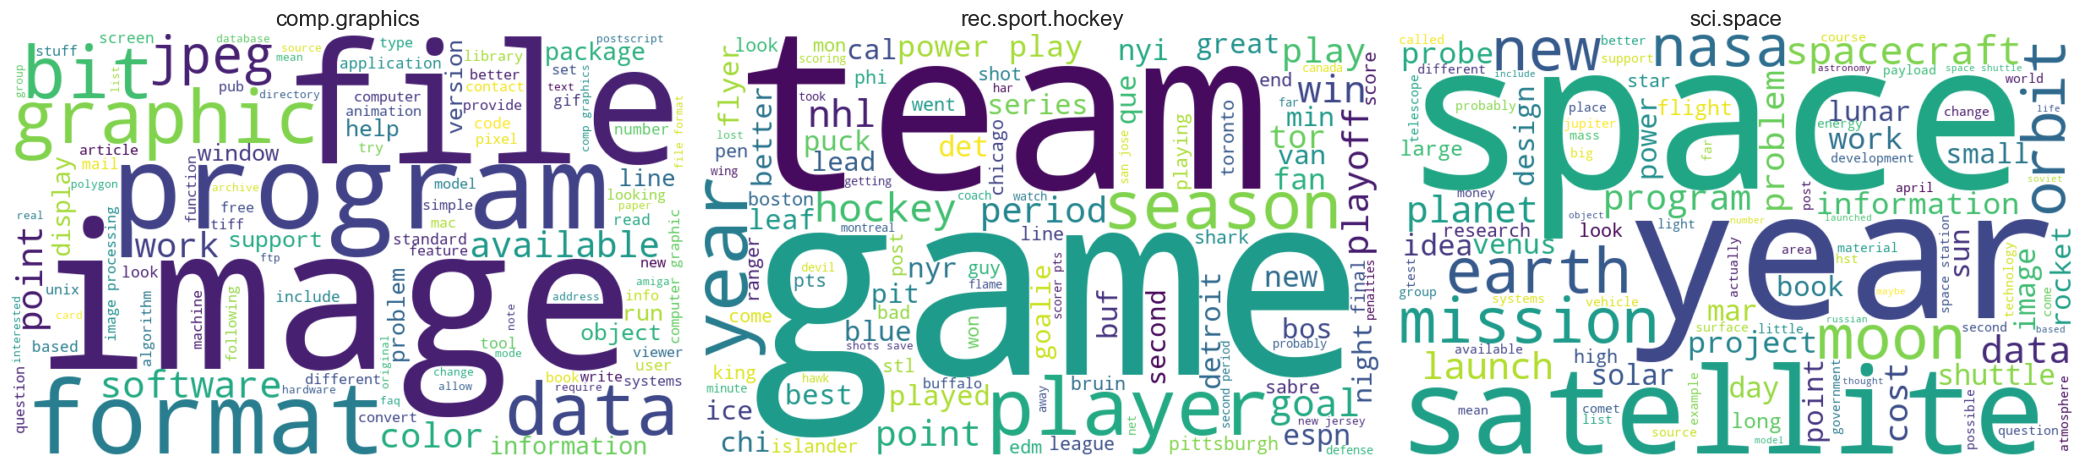

,comp.graphics,rec.sport.hockey,sci.space
1,image,game,space
2,graphics,team,earth
3,jpeg,hockey,nasa
4,file,play,launch
5,images,games,orbit
6,data,season,shuttle
7,bit,period,data
8,software,year,moon
9,available,pit,mission
10,format,nhl,new


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, category in zip(axes, categories):
    class_text = " ".join(texts.loc[texts["label"] == category, "clean_text"])
    cloud = WordCloud(width=800, height=500, background_color="white", max_words=100,
                      collocations=True, random_state=RANDOM_STATE).generate(class_text)
    ax.imshow(cloud.to_array(), interpolation="bilinear")
    ax.set_title(category, fontsize=16)
    ax.axis("off")
plt.tight_layout()
plt.show()

top_words = {category: pd.Series(" ".join(texts.loc[texts["label"] == category, "clean_text"]).split())
             .value_counts().head(10).index.tolist() for category in categories}
display(pd.DataFrame(top_words, index=range(1, 11)))

Хмари слів трьох класів суттєво відрізняються, і в кожній домінує лексика своєї теми: у `comp.graphics` слова про зображення, файли, формати та програми (image, graphics, file, program), у `rec.sport.hockey` хокейна лексика (game, team, hockey, players, season), у `sci.space` космічна тематика (space, nasa, launch, orbit). Спільних слів між хмарами мало, тому класи мають добре розділятися за лексикою, і представлення текстів через частоти слів (TF-IDF) підходить для класифікації.

### Векторизація TF-IDF

Вибірку ділимо у пропорції 80/20 зі стратифікацією. `TfidfVectorizer` навчаємо лише на навчальній вибірці. Враховуємо окремі слова й пари слів (`ngram_range=(1, 2)`), відкидаємо рідкісні (`min_df=2`) та надто часті (`max_df=0.9`) терміни, а `sublinear_tf=True` зменшує вплив багаторазових повторів слова в одному тексті.

In [17]:
X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    texts["clean_text"], texts["label"], test_size=0.2, stratify=texts["label"], random_state=RANDOM_STATE)
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_test_tfidf = vectorizer.transform(X_test_text)
print("TF-IDF train:", X_train_tfidf.shape, "| test:", X_test_tfidf.shape)

TF-IDF train: (2272, 35581) | test: (569, 35581)


### Класифікація текстів та оцінка якості

Порівнюємо три класичні моделі для текстів: Multinomial Naive Bayes, логістичну регресію та лінійний SVM. Метрики: accuracy, precision, recall і F1 (macro, тобто середнє по класах).

In [18]:
text_models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(dual=True, random_state=RANDOM_STATE),
}
text_rows = []
for name, model in text_models.items():
    model.fit(X_train_tfidf, y_train_text)
    y_pred = model.predict(X_test_tfidf)
    text_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test_text, y_pred),
        "Precision (macro)": precision_score(y_test_text, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test_text, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_test_text, y_pred, average="macro"),
    })
text_results = pd.DataFrame(text_rows).set_index("Модель").sort_values("F1 (macro)", ascending=False)
display(text_results.round(4))

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Модель,,,,
Logistic Regression,0.9631,0.9634,0.9632,0.9631
Linear SVM,0.9613,0.9616,0.9613,0.9613
Multinomial Naive Bayes,0.9596,0.9599,0.9597,0.9596


Детальний звіт і матриця помилок для найкращої моделі за macro F1:

Найкраща модель за F1 (macro): Logistic Regression
                  precision    recall  f1-score   support

   comp.graphics     0.9436    0.9840    0.9634       187
rec.sport.hockey     0.9892    0.9583    0.9735       192
       sci.space     0.9574    0.9474    0.9524       190

        accuracy                         0.9631       569
       macro avg     0.9634    0.9632    0.9631       569
    weighted avg     0.9636    0.9631    0.9631       569



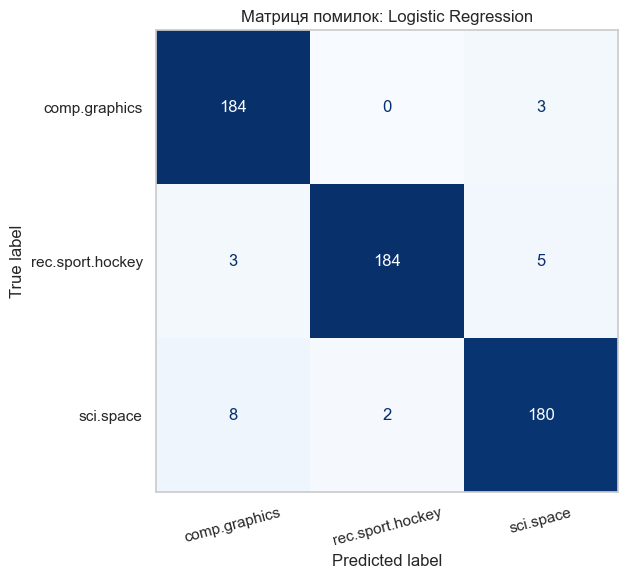

In [19]:
best_text_name = text_results.index[0]
y_pred_text = text_models[best_text_name].predict(X_test_tfidf)
print("Найкраща модель за F1 (macro):", best_text_name)
print(classification_report(y_test_text, y_pred_text, digits=4))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test_text, y_pred_text, labels=categories), display_labels=categories).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d", xticks_rotation=15)
ax.set_title(f"Матриця помилок: {best_text_name}")
ax.grid(False)
plt.show()

Аналіз помилок: довжина текстів і приклади неправильно класифікованих повідомлень.

In [20]:
test_lengths = X_test_text.str.split().str.len().to_numpy()
is_error = y_pred_text != y_test_text.to_numpy()
print("Помилок на тестовій вибірці:", is_error.sum(), "з", len(is_error))
print("Середня довжина правильно класифікованих текстів, слів:", round(test_lengths[~is_error].mean(), 1))
print("Середня довжина помилково класифікованих текстів, слів:", round(test_lengths[is_error].mean(), 1))
display(pd.DataFrame({"Текст": X_test_text[is_error].str[:150], "Справжній клас": y_test_text[is_error],
                      "Прогноз": y_pred_text[is_error]}).head(8))

Помилок на тестовій вибірці: 21 з 569
Середня довжина правильно класифікованих текстів, слів: 110.9
Середня довжина помилково класифікованих текстів, слів: 24.3


,Текст,Справжній клас,Прогноз
1937,faq sheet fails crash newsreader avoid crashing restarting machine look headers avoid reading faq problems reading faq,rec.sport.hockey,comp.graphics
1420,dean yes home reading paper details making post based wduq news sports related item wrong,rec.sport.hockey,comp.graphics
1897,worked support company problems toshiba short space years old screens went completely dodgy happened maybe fairly re...,comp.graphics,sci.space
451,usually apply unlevelshifting subtracting matrix multiplication results rgb space clamp resulting bytes conversion a...,comp.graphics,sci.space
549,letter addressed bettman post having pretty content entirely different entity addressed puts letter mail doubt figur...,rec.sport.hockey,sci.space
1251,definitely lemur elvis couldn spell listen songs,sci.space,rec.sport.hockey
727,instead stupid metric problems,sci.space,rec.sport.hockey
1151,recommend mail order distributor hockey equipment advance wayne,rec.sport.hockey,comp.graphics


Слова з найбільшими вагами логістичної регресії для кожного класу:

In [21]:
log_reg = text_models["Logistic Regression"]
vocabulary = vectorizer.get_feature_names_out()
display(pd.DataFrame({label: vocabulary[np.argsort(log_reg.coef_[i])[::-1][:15]]
                      for i, label in enumerate(log_reg.classes_)}))

,comp.graphics,rec.sport.hockey,sci.space
0,graphics,game,space
1,file,hockey,orbit
2,image,team,earth
3,computer,games,moon
4,looking,season,nasa
5,files,nhl,shuttle
6,version,play,launch
7,software,players,sky
8,advance,roger,solar
9,format,player,idea


### Висновки щодо класифікації текстів

- Усі три моделі показують високу якість (див. таблицю): тематична класифікація добре розв'язується лінійними моделями на TF-IDF, бо теми відрізняються словником. Найкращу модель за macro F1 визначено автоматично, її детальний звіт наведено вище.
- На матриці помилок більшість текстів лежить на діагоналі. Помилково класифіковані тексти в середньому коротші за правильно класифіковані: після видалення цитат і стоп-слів у них залишається лише кілька загальних слів, за якими тему важко визначити навіть людині.
- Слова з найбільшими вагами логістичної регресії збігаються зі словами, що домінують у WordCloud, тобто модель спирається саме на тематичну лексику класів.